In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import detector_model as dm

In [2]:
detector = dm.Detector()
source = dm.Source()

rng = np.random.default_rng(2026)

directions = source.emit(1.0, rng)

points = dm.sphere_intersections(
    source.position,
    directions,
    detector.R
)

assert np.allclose(
    np.linalg.norm(points, axis=1),
    detector.R
)

assert np.allclose(
    points,
    detector.R * directions
)

In [3]:
pmt_ids = detector.find_pmt(points)

n_detected_photons = np.count_nonzero(pmt_ids >= 0)

print("Испущено:", len(directions))
print("Попало на фотокатоды:", n_detected_photons)

Испущено: 10000
Попало на фотокатоды: 264


Если каждый из H фотонов независимо производит
\[K_i\sim\operatorname{Poisson}(a),\]
то
\[K_1+\ldots+K_H \sim\operatorname{Poisson}(aH).\]

Поэтому можно сразу разыграть суммарный сигнал каждого ФЭУ. Это точно эквивалентно отдельному пуассоновскому розыгрышу для каждого попавшего фотона.

rng.poisson принимает среднее распределения; если передать массив средних, возвращается массив случайных результатов.

In [4]:
detector = dm.Detector()

rng = np.random.default_rng(2026)

samples = detector.photoelectrons(
    np.ones(100_000, dtype=int),
    rng
)

print("Среднее:", samples.mean())
print("Дисперсия:", samples.var())

Среднее: 0.49653
Дисперсия: 0.4982479591


In [7]:
detector = dm.Detector()
source = dm.Source()

rng = np.random.default_rng(2026)

pe = dm.simulate_event(
    detector,
    source,
    E=1.0,
    rng=rng
)

Q = pe.sum()

print("Сигналы отдельных ФЭУ:")
print(pe)

print("Полный сигнал:", Q, "фотоэлектронов")

Сигналы отдельных ФЭУ:
[6 3 2 2 3 3 3 0 2 1 6 6 4 4 2 2 2 0 2 5 1 2 4 2 6 7 4 5 3 4 1 5 0 7 2 1 0
 5 3 3]
Полный сигнал: 123 фотоэлектронов


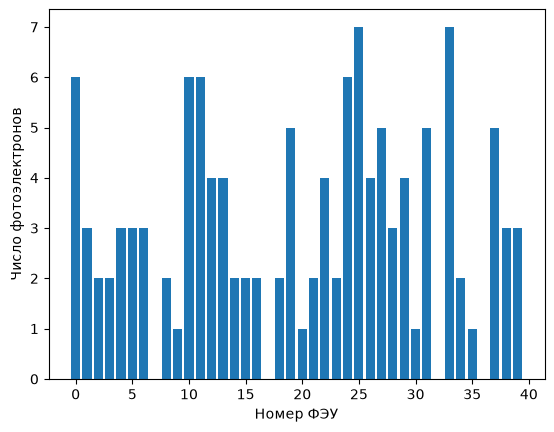

In [8]:
plt.bar(
    np.arange(detector.N),
    pe
)

plt.xlabel("Номер ФЭУ")
plt.ylabel("Число фотоэлектронов")

plt.show()

In [9]:
coverage = (
    detector.N * detector.r**2
    / (4 * detector.R**2)
)

expected_Q = (
    detector.a
    * source.Y
    * 1.0
    * coverage
)

print("Доля покрытия:", coverage)
print("Ожидаемый сигнал:", expected_Q)
print("Полученный сигнал:", Q)

Доля покрытия: 0.025000000000000005
Ожидаемый сигнал: 125.00000000000003
Полученный сигнал: 123
